#### Zomato Restaurant Rating Prediction
## Linear Regression, OLS, Ridge Regression and Lasso Regression

**Objective:** Predict a restaurant's `Aggregate rating` using available restaurant information.

**Dataset:** `Zomato Restaurant Dataset.csv`

> Keep the CSV file in the same folder as this notebook. Run the cells from top to bottom.

## 1. Install libraries
Run this cell once if the libraries are not already installed.

In [32]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 3. Load the dataset
If your CSV is stored somewhere else, replace the filename with its full path.

In [34]:
df = pd.read_csv("Zomato Restaurant Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 4. Inspect and clean the data
This notebook removes duplicate rows, excludes unrated restaurants (`Aggregate rating` = 0), and fills missing cuisine values. Other missing values are handled inside the preprocessing pipeline.

In [35]:
print("Missing values before cleaning:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Keep only restaurants with an actual rating
df["Aggregate rating"] = pd.to_numeric(df["Aggregate rating"], errors="coerce")
df = df.dropna(subset=["Aggregate rating"])
df = df[df["Aggregate rating"] > 0].copy()

# Fill missing cuisine descriptions
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

# Convert numeric columns safely
for col in ["Country Code", "Longitude", "Latitude",
            "Average Cost for two", "Price range", "Votes"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Log transforms help reduce strong right-skew in cost and vote counts
df["Log Cost"] = np.log1p(df["Average Cost for two"].clip(lower=0))
df["Log Votes"] = np.log1p(df["Votes"].clip(lower=0))

print("Shape after cleaning:", df.shape)
print("Rating range:", df["Aggregate rating"].min(), "to", df["Aggregate rating"].max())

Missing values before cleaning:


Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Duplicate rows: 0
Shape after cleaning: (7403, 23)
Rating range: 1.8 to 4.9


## 5. Select features and target

- **Target (y):** `Aggregate rating`
- **Features (X):** country, city, coordinates, cost, price range, votes, cuisines and service options.

`Rating color` and `Rating text` are deliberately excluded because they are derived from the rating and would leak information about the target into the model.

In [36]:
numeric_features = [
    "Country Code", "Longitude", "Latitude",
    "Log Cost", "Price range", "Log Votes"
]

categorical_features = [
    "City", "Cuisines", "Has Table booking",
    "Has Online delivery", "Is delivering now"
]

feature_columns = numeric_features + categorical_features

required_columns = feature_columns + ["Aggregate rating"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"These required columns are missing from the CSV: {missing_columns}")

X = df[feature_columns].copy()
y = df["Aggregate rating"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7403, 11)
Target shape: (7403,)


## 6. Split into training and testing data
The test set is held out and is used only for final evaluation.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 5922
Testing rows: 1481


## 7. Create preprocessing function

Numerical columns are median-imputed and standardized. Categorical columns are filled with their most frequent value and one-hot encoded.

A new preprocessor is created for each model to keep the model pipelines independent.

In [38]:
def make_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=20,
            drop="first",
            sparse_o
            utput=False
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )

## 8. Linear Regression

In [39]:
lr_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

print("Linear Regression")
print("R2:", r2_score(y_test, lr_predictions))
print("MAE:", mean_absolute_error(y_test, lr_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_predictions)))

Linear Regression
R2: 0.6051229788986308
MAE: 0.26462192812728985
RMSE: 0.3494678310063558


C:\Users\Asif\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


## 9. OLS Regression (Ordinary Least Squares)

Statsmodels OLS fits the least-squares model. The preprocessing is fitted on the training set only and then applied to the test set. A constant/intercept is added to both.

In [40]:
ols_preprocessor = make_preprocessor()

X_train_ols = ols_preprocessor.fit_transform(X_train)
X_test_ols = ols_preprocessor.transform(X_test)

X_train_ols = sm.add_constant(X_train_ols, has_constant="add")
X_test_ols = sm.add_constant(X_test_ols, has_constant="add")

ols_model = sm.OLS(y_train, X_train_ols).fit()
ols_predictions = ols_model.predict(X_test_ols)

print(ols_model.summary())

print("\nOLS test results")
print("R2:", r2_score(y_test, ols_predictions))
print("MAE:", mean_absolute_error(y_test, ols_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ols_predictions)))

                            OLS Regression Results                            
Dep. Variable:       Aggregate rating   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.563
Method:                 Least Squares   F-statistic:                     120.4
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:16:35   Log-Likelihood:                -2388.4
No. Observations:                5922   AIC:                             4907.
Df Residuals:                    5857   BIC:                             5341.
Df Model:                          64                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.3548      0.098     34.290      0.0

C:\Users\Asif\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


## 10. Ridge Regression
GridSearchCV selects the regularization strength (`alpha`) using cross-validation on the training data.

In [41]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", Ridge())
])

ridge_params = {"model__alpha": [0.01, 0.1, 1, 10, 100]}

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
ridge_predictions = ridge_model.predict(X_test)

print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("R2:", r2_score(y_test, ridge_predictions))
print("MAE:", mean_absolute_error(y_test, ridge_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, ridge_predictions)))

Best Ridge alpha: 0.1
R2: 0.6051254831150397
MAE: 0.2646295489138177
RMSE: 0.3494667228835511


C:\Users\Asif\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


## 11. Lasso Regression
Lasso can shrink some coefficients to zero. GridSearchCV selects `alpha` using training data only.

In [42]:
lasso_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", Lasso(max_iter=20000))
])

lasso_params = {"model__alpha": [0.001, 0.01, 0.1, 1, 10]}

lasso_search = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_
lasso_predictions = lasso_model.predict(X_test)

print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("R2:", r2_score(y_test, lasso_predictions))
print("MAE:", mean_absolute_error(y_test, lasso_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lasso_predictions)))

Best Lasso alpha: 0.001
R2: 0.588985786465072
MAE: 0.2686396724403108
RMSE: 0.35653707233630133


C:\Users\Asif\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


## 12. Compare all four models
Higher R² is better; lower MAE and RMSE are better. Use the held-out test results for comparison.

In [43]:
predictions = {
    "Linear Regression": lr_predictions,
    "OLS Regression": ols_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions
}

results = pd.DataFrame([
    {
        "Algorithm": name,
        "R2 Score": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred))
    }
    for name, pred in predictions.items()
])

display(results.sort_values("RMSE").round(4))

,Algorithm,R2 Score,MAE,RMSE
2,Ridge Regression,0.6051,0.2646,0.3495
0,Linear Regression,0.6051,0.2646,0.3495
1,OLS Regression,0.6051,0.2646,0.3495
3,Lasso Regression,0.5890,0.2686,0.3565


## 13. Visualize model performance

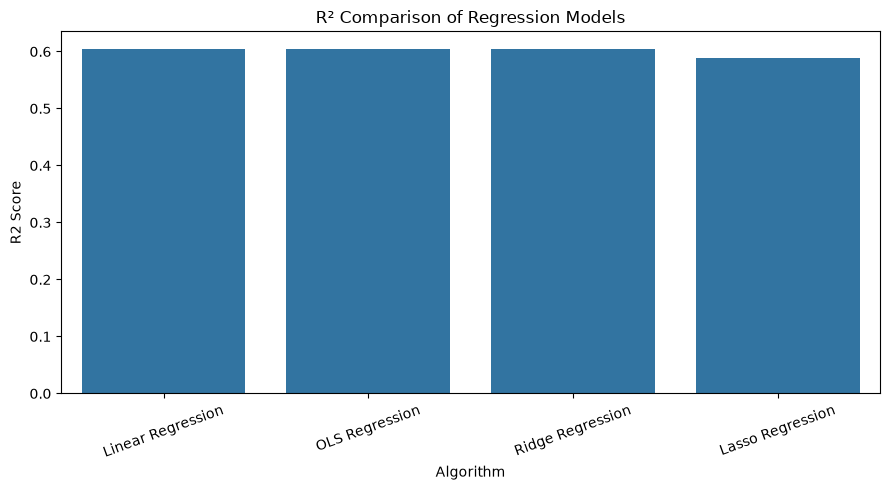

In [44]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results, x="Algorithm", y="R2 Score")
plt.title("R² Comparison of Regression Models")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 14. Actual vs predicted ratings for the lowest-RMSE model

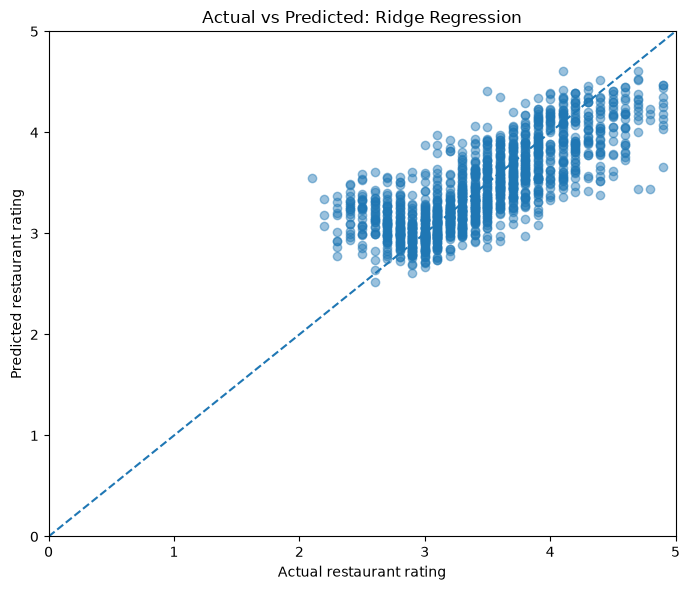

Lowest-RMSE model: Ridge Regression


In [45]:
best_model_name = results.loc[results["RMSE"].idxmin(), "Algorithm"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.45)
plt.plot([0, 5], [0, 5], linestyle="--")
plt.xlabel("Actual restaurant rating")
plt.ylabel("Predicted restaurant rating")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

print("Lowest-RMSE model:", best_model_name)

## 15. Conclusion guide

After running the notebook, use the comparison table to report the actual results.

- **R²:** proportion of variation in restaurant ratings explained by the model.
- **MAE:** average absolute prediction error, in rating points.
- **RMSE:** prediction error measure that penalizes larger errors more strongly.

Do not write a model accuracy percentage unless you define how it was calculated. R² is not simply classification accuracy.

**Important interpretation:** OLS and ordinary Linear Regression minimize the same squared-error objective. With the same design matrix and intercept, their predictions should be nearly identical. Ridge and Lasso add regularization penalties.